In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [51]:
day3_path = "../data/feature_data/APL_Day3_Feature_Engineered.csv"

df_day3 = pd.read_csv(
    day3_path,
    encoding="cp1252",
    low_memory=False
)

print("Day 3 feature-engineered dataset loaded successfully.")
print("Shape:", df_day3.shape)

Day 3 feature-engineered dataset loaded successfully.
Shape: (180519, 54)


## Day 4 Working copy

In [52]:
df_day4 = df_day3.copy()

print("Day 4 working copy created.")
print("Shape:", df_day4.shape)

Day 4 working copy created.
Shape: (180519, 54)


## Initial Delivery Performance Check

In [53]:
delivery_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping_Delay_Days",
    "Is_Delayed",
    "Is_On_Time",
    "Early_Delivery_Days",
    "Delay_Severity",
    "Delivery_Efficiency_Ratio",
    "Shipping Mode",
    "Market",
    "Order Region",
    "Region_Market",
    "Late_delivery_risk"
]

display(df_day4[delivery_columns].head(10))

,Days for shipping (real),Days for shipment (scheduled),Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Shipping Mode,Market,Order Region,Region_Market,Late_delivery_risk
0,6,4,2,1,0,0,Major Delay,0.666667,Standard Class,Pacific Asia,South Asia,Pacific Asia - South Asia,1
1,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,LATAM,Central America,LATAM - Central America,0
2,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,LATAM,Central America,LATAM - Central America,0
3,6,4,2,1,0,0,Major Delay,0.666667,Standard Class,USCA,East of USA,USCA - East of USA,1
4,6,4,2,1,0,0,Major Delay,0.666667,Standard Class,USCA,East of USA,USCA - East of USA,1
5,6,4,2,1,0,0,Major Delay,0.666667,Standard Class,USCA,East of USA,USCA - East of USA,1
6,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,LATAM,Central America,LATAM - Central America,0
7,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,LATAM,Central America,LATAM - Central America,0
8,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,Europe,Southern Europe,Europe - Southern Europe,0
9,4,4,0,0,1,0,On Time / Early,1.000000,Standard Class,LATAM,Central America,LATAM - Central America,0


In [54]:
df_day4[delivery_columns].info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 13 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Days for shipping (real)       180519 non-null  int64  
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Shipping_Delay_Days            180519 non-null  int64  
 3   Is_Delayed                     180519 non-null  int64  
 4   Is_On_Time                     180519 non-null  int64  
 5   Early_Delivery_Days            180519 non-null  int64  
 6   Delay_Severity                 180519 non-null  str    
 7   Delivery_Efficiency_Ratio      175439 non-null  float64
 8   Shipping Mode                  180519 non-null  str    
 9   Market                         180519 non-null  str    
 10  Order Region                   180519 non-null  str    
 11  Region_Market                  180519 non-null  str    
 12  Late_delivery_risk             180519 non

## Create a delivery Status Feature

In [55]:
df_day4["Delivery_Status"] = np.select(
    [
        df_day4["Shipping_Delay_Days"] < 0,
        df_day4["Shipping_Delay_Days"] == 0,
        df_day4["Shipping_Delay_Days"] > 0
    ],
    [
        "Early",
        "On Time",
        "Delayed"
    ],
    default="Unknown"
)

In [56]:
df_day4["Delivery_Status"].value_counts()

Delivery_Status
Delayed    103400
Early       43366
On Time     33753
Name: count, dtype: int64

In [57]:
delivery_status_pct = (
    df_day4["Delivery_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(delivery_status_pct)

Delivery_Status
Delayed    57.28
Early      24.02
On Time    18.70
Name: proportion, dtype: float64

## Overall Delivery Performance 

In [58]:
total_shipments = len(df_day4)

delayed_shipments = (
    df_day4["Delivery_Status"] == "Delayed"
).sum()

on_time_shipments = (
    df_day4["Delivery_Status"] == "On Time"
).sum()

early_shipments = (
    df_day4["Delivery_Status"] == "Early"
).sum()

delivery_performance = pd.DataFrame({
    "Metric": [
        "Total Shipments",
        "Delayed Shipments",
        "On-Time Shipments",
        "Early Shipments",
        "Delay Rate (%)",
        "On-Time Rate (%)",
        "Early Delivery Rate (%)"
    ],
    "Value": [
        total_shipments,
        delayed_shipments,
        on_time_shipments,
        early_shipments,
        round(delayed_shipments / total_shipments * 100, 2),
        round(on_time_shipments / total_shipments * 100, 2),
        round(early_shipments / total_shipments * 100, 2)
    ]
})

display(delivery_performance)

,Metric,Value
0,Total Shipments,180519.00
1,Delayed Shipments,103400.00
2,On-Time Shipments,33753.00
3,Early Shipments,43366.00
4,Delay Rate (%),57.28
5,On-Time Rate (%),18.70
6,Early Delivery Rate (%),24.02


## Visualize Delivery Status

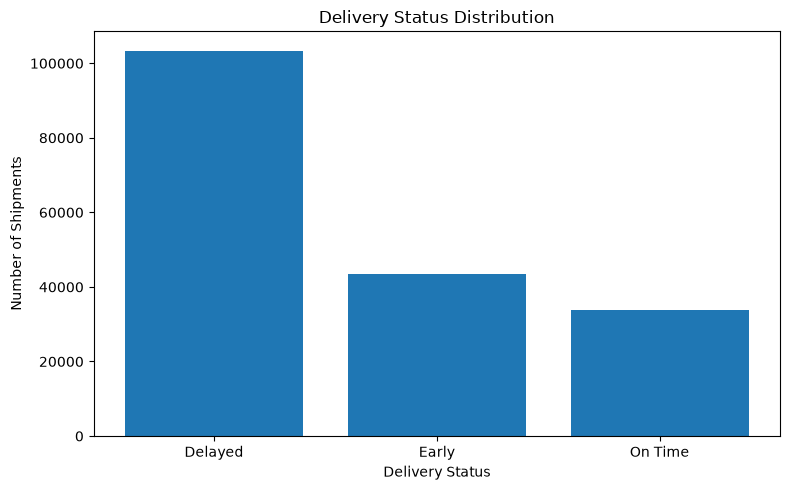

In [59]:
status_counts = df_day4["Delivery_Status"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.title("Delivery Status Distribution")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

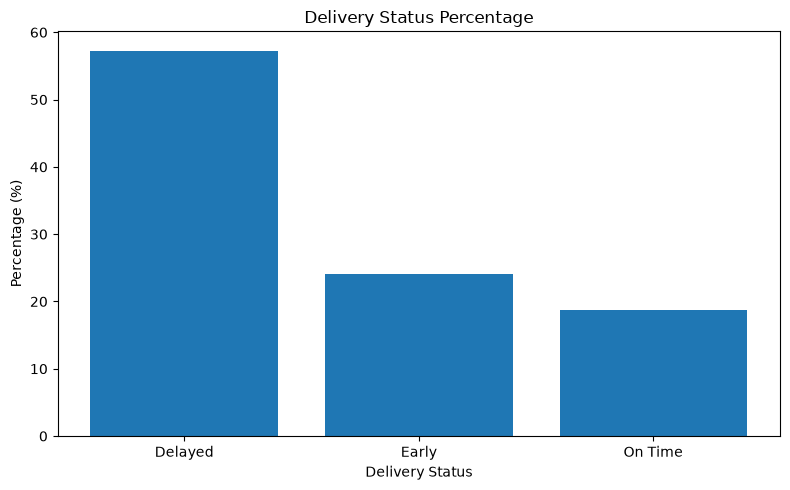

In [60]:
plt.figure(figsize=(8, 5))

plt.bar(
    delivery_status_pct.index,
    delivery_status_pct.values
)

plt.title("Delivery Status Percentage")
plt.xlabel("Delivery Status")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

## Analyze Shipping Delay

In [61]:
delay_statistics = df_day4["Shipping_Delay_Days"].describe()

display(delay_statistics)

count    180519.000000
mean          0.565807
std           1.490966
min          -2.000000
25%           0.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: Shipping_Delay_Days, dtype: float64

In [62]:
delay_summary = pd.DataFrame({
    "Metric": [
        "Average Shipping Delay",
        "Median Shipping Delay",
        "Minimum Shipping Delay",
        "Maximum Shipping Delay",
        "Standard Deviation"
    ],
    "Days": [
        df_day4["Shipping_Delay_Days"].mean(),
        df_day4["Shipping_Delay_Days"].median(),
        df_day4["Shipping_Delay_Days"].min(),
        df_day4["Shipping_Delay_Days"].max(),
        df_day4["Shipping_Delay_Days"].std()
    ]
})

display(delay_summary.round(2))

,Metric,Days
0,Average Shipping Delay,0.57
1,Median Shipping Delay,1.00
2,Minimum Shipping Delay,-2.00
3,Maximum Shipping Delay,4.00
4,Standard Deviation,1.49


## Analyze Delayed Shipments Only

In [63]:
delayed_df = df_day4[
    df_day4["Shipping_Delay_Days"] > 0
].copy()

print("Delayed shipments:", len(delayed_df))

Delayed shipments: 103400


In [64]:
delayed_statistics = delayed_df["Shipping_Delay_Days"].describe()

display(delayed_statistics)

count    103400.000000
mean          1.616741
std           0.882034
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           4.000000
Name: Shipping_Delay_Days, dtype: float64

In [65]:
average_delay_delayed_only = delayed_df["Shipping_Delay_Days"].mean()
median_delay_delayed_only = delayed_df["Shipping_Delay_Days"].median()

print("Average delay among delayed shipments:",
      round(average_delay_delayed_only, 2))

print("Median delay among delayed shipments:",
      round(median_delay_delayed_only, 2))

Average delay among delayed shipments: 1.62
Median delay among delayed shipments: 1.0


## Delay Severity Analysis

In [66]:
delay_severity_counts = (
    df_day4["Delay_Severity"]
    .value_counts()
)

display(delay_severity_counts)

Delay_Severity
On Time / Early    77119
Minor Delay        60647
Major Delay        42753
Name: count, dtype: int64

In [67]:
delay_severity_pct = (
    df_day4["Delay_Severity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(delay_severity_pct)

Delay_Severity
On Time / Early    42.72
Minor Delay        33.60
Major Delay        23.68
Name: proportion, dtype: float64

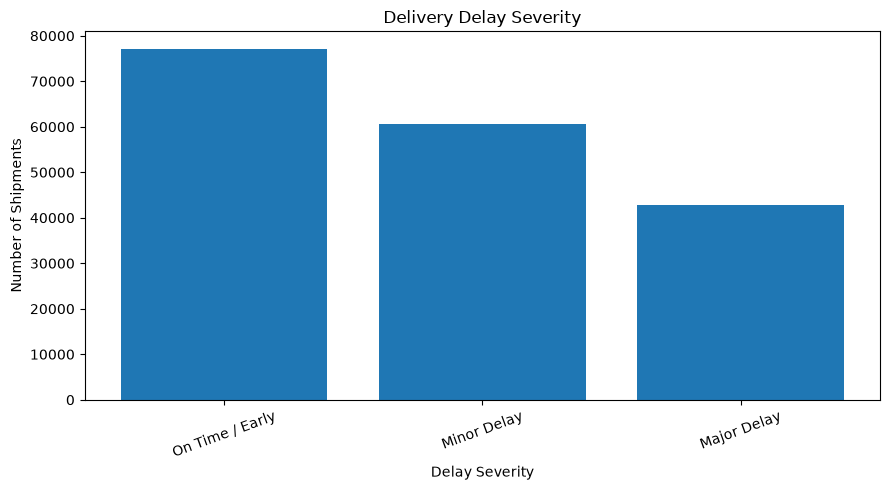

In [68]:
plt.figure(figsize=(9, 5))

plt.bar(
    delay_severity_counts.index,
    delay_severity_counts.values
)

plt.title("Delivery Delay Severity")
plt.xlabel("Delay Severity")
plt.ylabel("Number of Shipments")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Shipping Mode Performance

In [69]:
shipping_mode_volume = (
    df_day4["Shipping Mode"]
    .value_counts()
)

display(shipping_mode_volume)

Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

In [70]:
shipping_mode_performance = (
    df_day4
    .groupby("Shipping Mode")
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean"),
        Average_Efficiency=("Delivery_Efficiency_Ratio", "mean")
    )
)

shipping_mode_performance["Delay_Rate_%"] = (
    shipping_mode_performance["Delayed_Shipments"]
    / shipping_mode_performance["Total_Shipments"]
    * 100
)

shipping_mode_performance = (
    shipping_mode_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

display(shipping_mode_performance.round(2))

,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Average_Efficiency,Delay_Rate_%
Shipping Mode,,,,,
First Class,27814,27814,1.00,0.50,100.00
Second Class,35216,28078,1.99,0.58,79.73
Same Day,9737,4657,0.48,0.00,47.83
Standard Class,107752,42851,-0.00,1.16,39.77


## Shipping Mode Visualization

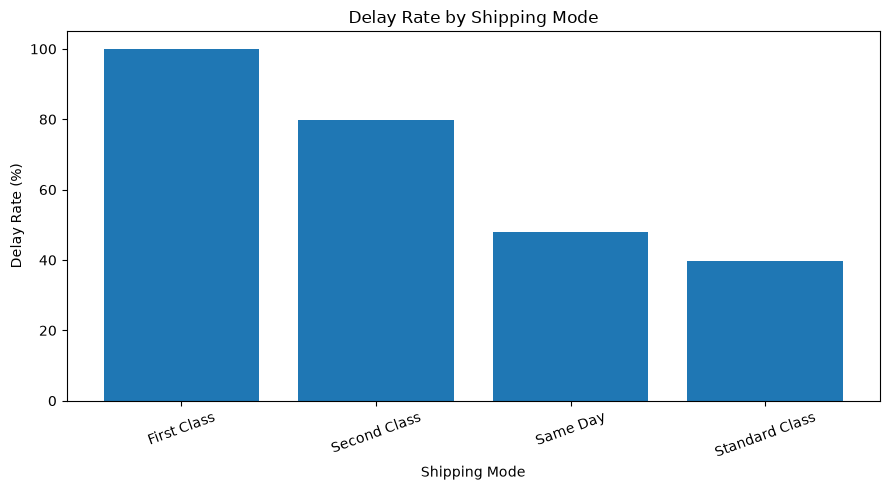

In [71]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_mode_performance.index,
    shipping_mode_performance["Delay_Rate_%"]
)

plt.title("Delay Rate by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

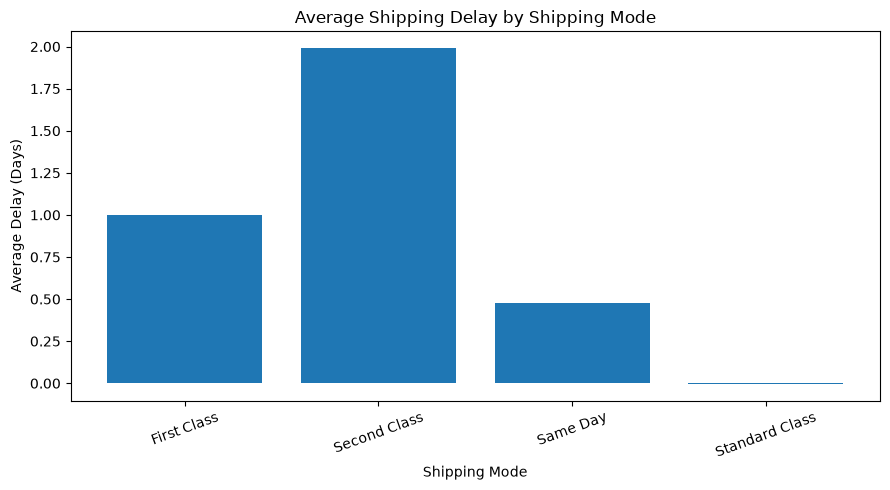

In [72]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_mode_performance.index,
    shipping_mode_performance["Average_Delay_Days"]
)

plt.title("Average Shipping Delay by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Delay (Days)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Market-Level Delivery Performance

In [73]:
market_performance = (
    df_day4
    .groupby("Market")
    .agg(
        Total_Shipments=("Market", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

market_performance["Delay_Rate_%"] = (
    market_performance["Delayed_Shipments"]
    / market_performance["Total_Shipments"]
    * 100
)

market_performance = (
    market_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

display(market_performance.round(2))

,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_%
Market,,,,
Europe,50252,28989,0.57,57.69
Pacific Asia,41260,23649,0.57,57.32
USCA,25799,14744,0.57,57.15
LATAM,51594,29420,0.56,57.02
Africa,11614,6598,0.56,56.81


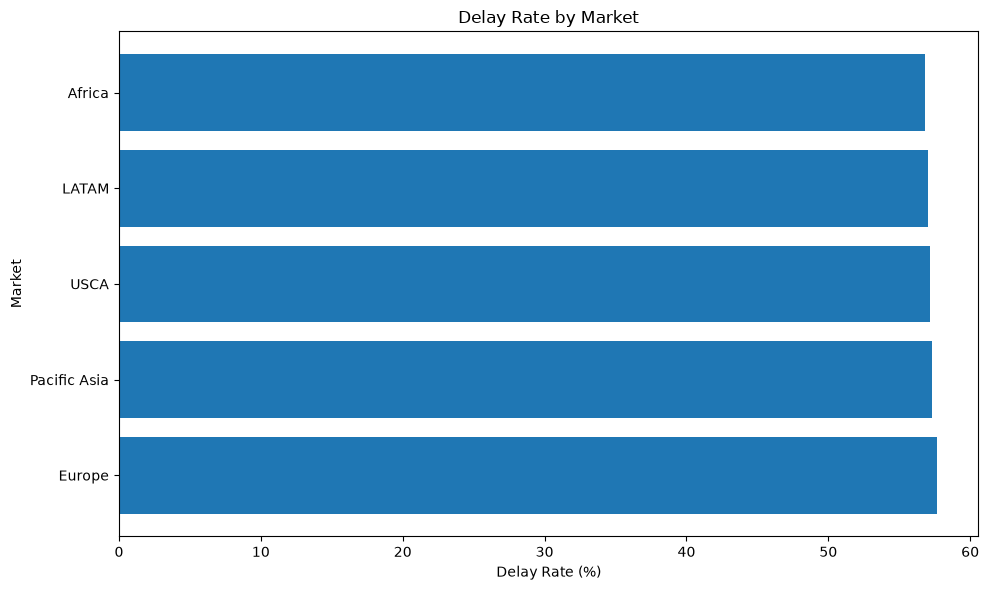

In [74]:
plt.figure(figsize=(10, 6))

plt.barh(
    market_performance.index,
    market_performance["Delay_Rate_%"]
)

plt.title("Delay Rate by Market")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Market")
plt.tight_layout()
plt.show()

## Regional Delivery Performance

In [75]:
region_performance = (
    df_day4
    .groupby("Order Region")
    .agg(
        Total_Shipments=("Order Region", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

region_performance["Delay_Rate_%"] = (
    region_performance["Delayed_Shipments"]
    / region_performance["Total_Shipments"]
    * 100
)

region_performance = (
    region_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

display(region_performance.round(2))

,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_%
Order Region,,,,
Central Africa,1677,1018,0.64,60.70
Western Europe,27109,15863,0.60,58.52
South Asia,7731,4523,0.60,58.50
South of USA,4045,2350,0.58,58.10
Southeast Asia,9539,5531,0.56,57.98
East of USA,6915,4009,0.58,57.98
West Asia,6009,3455,0.57,57.50
East Africa,1852,1064,0.57,57.45
Eastern Europe,3920,2252,0.58,57.45


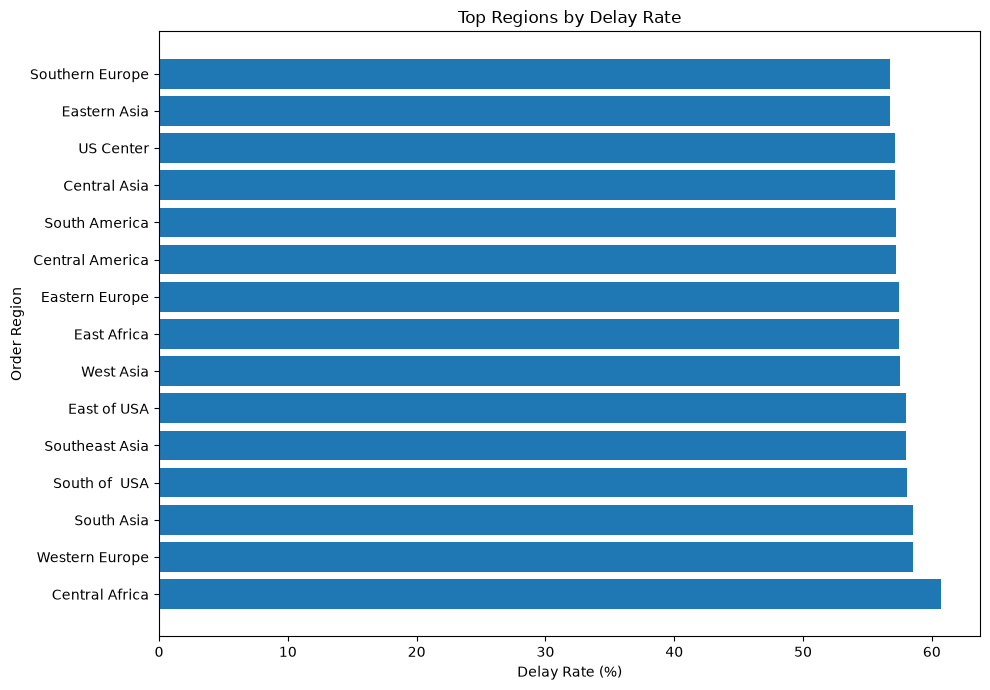

In [76]:
top_regions = region_performance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_regions.index,
    top_regions["Delay_Rate_%"]
)

plt.title("Top Regions by Delay Rate")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Order Region")
plt.tight_layout()
plt.show()

## Region + Market Analysis

In [77]:
region_market_performance = (
    df_day4
    .groupby("Region_Market")
    .agg(
        Total_Shipments=("Region_Market", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

region_market_performance["Delay_Rate_%"] = (
    region_market_performance["Delayed_Shipments"]
    / region_market_performance["Total_Shipments"]
    * 100
)

region_market_performance = (
    region_market_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

display(region_market_performance.head(15).round(2))

,Total_Shipments,Delayed_Shipments,Average_Delay_Days,Delay_Rate_%
Region_Market,,,,
Africa - Central Africa,1677,1018,0.64,60.70
Europe - Western Europe,27109,15863,0.60,58.52
Pacific Asia - South Asia,7731,4523,0.60,58.50
USCA - South of USA,4045,2350,0.58,58.10
Pacific Asia - Southeast Asia,9539,5531,0.56,57.98
USCA - East of USA,6915,4009,0.58,57.98
Pacific Asia - West Asia,6009,3455,0.57,57.50
Africa - East Africa,1852,1064,0.57,57.45
Europe - Eastern Europe,3920,2252,0.58,57.45


## Scheduled vs Actual Shipping Time

In [78]:
shipping_time_summary = pd.DataFrame({
    "Metric": [
        "Average Scheduled Shipping Days",
        "Average Actual Shipping Days",
        "Average Difference"
    ],
    "Days": [
        df_day4["Days for shipment (scheduled)"].mean(),
        df_day4["Days for shipping (real)"].mean(),
        df_day4["Shipping_Delay_Days"].mean()
    ]
})

display(shipping_time_summary.round(2))

,Metric,Days
0,Average Scheduled Shipping Days,2.93
1,Average Actual Shipping Days,3.50
2,Average Difference,0.57


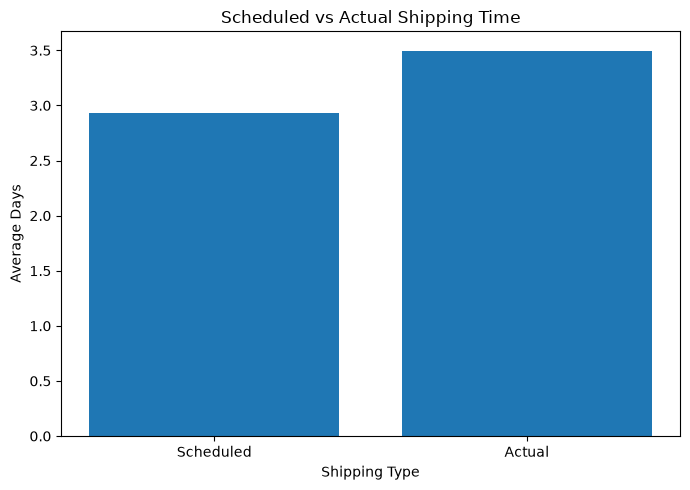

In [79]:
comparison = pd.DataFrame({
    "Shipping Type": [
        "Scheduled",
        "Actual"
    ],
    "Average Days": [
        df_day4["Days for shipment (scheduled)"].mean(),
        df_day4["Days for shipping (real)"].mean()
    ]
})

plt.figure(figsize=(7, 5))

plt.bar(
    comparison["Shipping Type"],
    comparison["Average Days"]
)

plt.title("Scheduled vs Actual Shipping Time")
plt.xlabel("Shipping Type")
plt.ylabel("Average Days")
plt.tight_layout()
plt.show()

## Delivery Efficiency Analysis

In [80]:
efficiency_summary = df_day4[
    "Delivery_Efficiency_Ratio"
].describe()

display(efficiency_summary)

count    175439.000000
mean          0.909575
std           0.510299
min           0.000000
25%           0.500000
50%           0.800000
75%           1.000000
max           2.000000
Name: Delivery_Efficiency_Ratio, dtype: float64

In [81]:
efficiency_by_mode = (
    df_day4
    .groupby("Shipping Mode")["Delivery_Efficiency_Ratio"]
    .mean()
    .sort_values()
)

display(efficiency_by_mode.round(3))

Shipping Mode
Same Day          0.000
First Class       0.500
Second Class      0.582
Standard Class    1.162
Name: Delivery_Efficiency_Ratio, dtype: float64

## Delivery Performance by Delay Status

In [82]:
delivery_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipments",
        "Delayed Shipments",
        "On-Time Shipments",
        "Early Shipments",
        "Delay Rate (%)",
        "On-Time Rate (%)",
        "Early Rate (%)",
        "Average Delay (All Shipments)",
        "Average Delay (Delayed Shipments)",
        "Maximum Delay"
    ],
    "Value": [
        len(df_day4),
        (df_day4["Delivery_Status"] == "Delayed").sum(),
        (df_day4["Delivery_Status"] == "On Time").sum(),
        (df_day4["Delivery_Status"] == "Early").sum(),
        (df_day4["Delivery_Status"] == "Delayed").mean() * 100,
        (df_day4["Delivery_Status"] == "On Time").mean() * 100,
        (df_day4["Delivery_Status"] == "Early").mean() * 100,
        df_day4["Shipping_Delay_Days"].mean(),
        delayed_df["Shipping_Delay_Days"].mean(),
        df_day4["Shipping_Delay_Days"].max()
    ]
})

display(delivery_kpis.round(2))

,Metric,Value
0,Total Shipments,180519.00
1,Delayed Shipments,103400.00
2,On-Time Shipments,33753.00
3,Early Shipments,43366.00
4,Delay Rate (%),57.28
5,On-Time Rate (%),18.70
6,Early Rate (%),24.02
7,Average Delay (All Shipments),0.57
8,Average Delay (Delayed Shipments),1.62
9,Maximum Delay,4.00


## Important Cross-Analysis

In [83]:
mode_region_performance = (
    df_day4
    .groupby(["Shipping Mode", "Order Region"])
    .agg(
        Total_Shipments=("Order Region", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean")
    )
)

mode_region_performance["Delay_Rate_%"] = (
    mode_region_performance["Delayed_Shipments"]
    / mode_region_performance["Total_Shipments"]
    * 100
)

mode_region_performance = (
    mode_region_performance
    .sort_values("Delay_Rate_%", ascending=False)
)

display(mode_region_performance.head(20).round(2))

Total_Shipments  Delayed_Shipments  \
Shipping Mode Order Region                                          
First Class   Canada                       184                184   
              Caribbean                   1193               1193   
              Central Africa               300                300   
              Central America             4382               4382   
              Central Asia                  63                 63   
              East Africa                  280                280   
              East of USA                 1089               1089   
              Eastern Asia                1043               1043   
              Eastern Europe               658                658   
              North Africa                 486                486   
              Northern Europe             1418               1418   
              Oceania                     1366               1366   
              South America               2311               2311   
              South Asia                  1283               1283   
              South of  USA                600                600   
              Southeast Asia              1552               1552   
              Southern Africa              198                198   
              Southern Europe             1504               1504   
              US Center                    986                986   
              West Africa                  463                463   

                               Average_Delay_Days  Delay_Rate_%  
Shipping Mode Order Region                                       
First Class   Canada                          1.0         100.0  
              Caribbean                       1.0         100.0  
              Central Africa                  1.0         100.0  
              Central America                 1.0         100.0  
              Central Asia                    1.0         100.0  
              East Africa                     1.0         100.0  
              East of USA                     1.0         100.0  
              Eastern Asia                    1.0         100.0  
              Eastern Europe                  1.0         100.0  
              North Africa                    1.0         100.0  
              Northern Europe                 1.0         100.0  
              Oceania                         1.0         100.0  
              South America                   1.0         100.0  
              South Asia                      1.0         100.0  
              South of  USA                   1.0         100.0  
              Southeast Asia                  1.0         100.0  
              Southern Africa                 1.0         100.0  
              Southern Europe                 1.0         100.0  
              US Center                       1.0         100.0  
              West Africa                     1.0         100.0

## Create a Delay Distribution

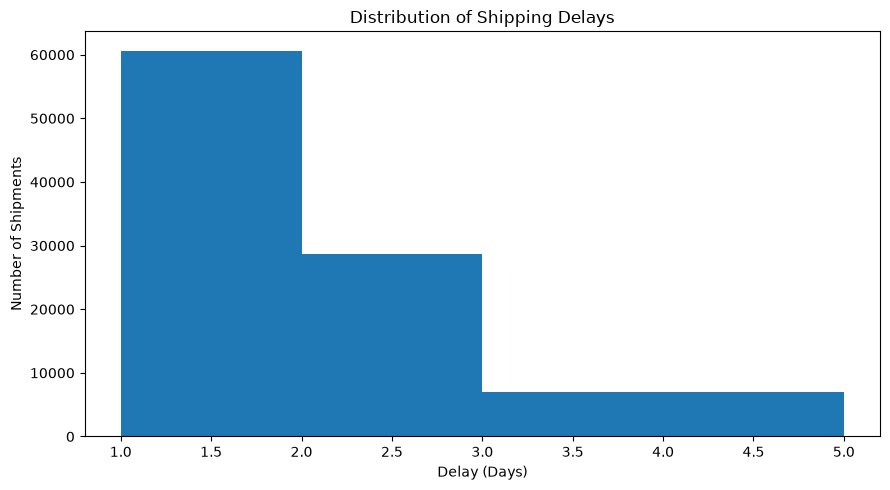

In [84]:
plt.figure(figsize=(9, 5))

plt.hist(
    delayed_df["Shipping_Delay_Days"],
    bins=range(
        int(delayed_df["Shipping_Delay_Days"].min()),
        int(delayed_df["Shipping_Delay_Days"].max()) + 2
    )
)

plt.title("Distribution of Shipping Delays")
plt.xlabel("Delay (Days)")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

## Day 4 Insight Generation

In [85]:
highest_delay_mode = shipping_mode_performance["Delay_Rate_%"].idxmax()
highest_delay_market = market_performance["Delay_Rate_%"].idxmax()
highest_delay_region = region_performance["Delay_Rate_%"].idxmax()

print("Highest delay-rate shipping mode:", highest_delay_mode)
print("Highest delay-rate market:", highest_delay_market)
print("Highest delay-rate region:", highest_delay_region)

Highest delay-rate shipping mode: First Class
Highest delay-rate market: Europe
Highest delay-rate region: Central Africa


In [86]:
print(
    "Highest shipping-mode delay rate:",
    round(shipping_mode_performance.loc[
        highest_delay_mode, "Delay_Rate_%"
    ], 2),
    "%"
)

print(
    "Highest market delay rate:",
    round(market_performance.loc[
        highest_delay_market, "Delay_Rate_%"
    ], 2),
    "%"
)

print(
    "Highest regional delay rate:",
    round(region_performance.loc[
        highest_delay_region, "Delay_Rate_%"
    ], 2),
    "%"
)

Highest shipping-mode delay rate: 100.0 %
Highest market delay rate: 57.69 %
Highest regional delay rate: 60.7 %


## Day 4 Validation 

In [87]:
day4_validation = {
    "Row Count Preserved": len(df_day4) == 180519,
    "No Duplicate Rows": df_day4.duplicated().sum() == 0,
    "Delivery Status Created": "Delivery_Status" in df_day4.columns,
    "Valid Delivery Status": set(
        df_day4["Delivery_Status"].dropna().unique()
    ).issubset({"Early", "On Time", "Delayed", "Unknown"}),
    "Delayed Flag Consistent": (
        df_day4["Is_Delayed"]
        ==
        (df_day4["Shipping_Delay_Days"] > 0).astype(int)
    ).all(),
    "On-Time Flag Consistent": (
        df_day4["Is_On_Time"]
        ==
        (df_day4["Shipping_Delay_Days"] == 0).astype(int)
    ).all()
}

day4_validation_report = pd.DataFrame(
    list(day4_validation.items()),
    columns=["Validation", "Status"]
)

display(day4_validation_report)

,Validation,Status
0,Row Count Preserved,True
1,No Duplicate Rows,True
2,Delivery Status Created,True
3,Valid Delivery Status,True
4,Delayed Flag Consistent,True
5,On-Time Flag Consistent,True


In [88]:
if day4_validation_report["Status"].all():
    print("DAY 4 DELIVERY PERFORMANCE: PASS")
else:
    print("DAY 4 DELIVERY PERFORMANCE: CHECK REQUIRED")

DAY 4 DELIVERY PERFORMANCE: PASS


## Saving Day 4 Analysis Outputs

In [89]:
import os

os.makedirs("../data/analysis_data", exist_ok=True)

In [90]:
day4_path = "../data/analysis_data/APL_Day4_Delivery_Performance.csv"

df_day4.to_csv(
    day4_path,
    index=False,
    encoding="cp1252"
)

print("Day 4 dataset saved successfully.")
print(day4_path)

Day 4 dataset saved successfully.
../data/analysis_data/APL_Day4_Delivery_Performance.csv


### Saving KPI table

In [91]:
kpi_path = "../data/analysis_data/APL_Day4_Delivery_KPIs.csv"

delivery_kpis.to_csv(
    kpi_path,
    index=False,
    encoding="utf-8"
)

print("Day 4 KPI report saved successfully.")
print(kpi_path)

Day 4 KPI report saved successfully.
../data/analysis_data/APL_Day4_Delivery_KPIs.csv


### Saving performance table

In [92]:
shipping_mode_path = "../data/analysis_data/APL_Day4_Shipping_Mode_Performance.csv"

shipping_mode_performance.to_csv(
    shipping_mode_path,
    index=False,
    encoding="utf-8"
)

market_path = "../data/analysis_data/APL_Day4_Market_Performance.csv"

market_performance.to_csv(
    market_path,
    index=False,
    encoding="utf-8"
)

region_path = "../data/analysis_data/APL_Day4_Region_Performance.csv"

region_performance.to_csv(
    region_path,
    index=False,
    encoding="utf-8"
)